# Question 4 LINEAR REGRESSION

In [489]:

#data_generator.py
import numpy as np

def fun(x):
    
    #print("compute a simple quadratic function f:R^5 -> R.")

    return 1.3 + 2.*x[0] - 1.1*x[1] + 0.7*x[2]  + 1.2*x[3] + \
            0.4* (x[0]**2) -1.5 *x[1]*x[3] - 0.7 * (x[4]**2) 

def postfix(N,d,sigma):
    """Converts parameters into a handy string, to be appended to file names."""
    return "_N_%d_d_%d" % (N,d) \
         + "_sig_%s" % str(sigma).replace(".","_")      


if __name__ == "__main__":        
    # Set random seed for reproducibility    
    np.random.seed(42)


    # Number of samples
    N = 1000

    # Noise variance 
    sigma = 0.01


    # Feature dimension
    #d = 40 #question 4.3
    d = 40  #question 4.2
  
    print("Generating dataset with N = %d, σ = %f, d = %d..." % (N,sigma,d), end="")

    # Generate random features
    X = np.random.randn(N, d)

    # Generate pure labels
    y = []

    for i in range(N):
        y.append(
                    fun(X[i,:])
                    )
    y = np.array(y)

    # Add noise to labels
    err = np.random.normal(scale = sigma, size = N)
    y = y + err

    print(" done")

    psfx = postfix(N,d,sigma)

    print("Saving X and y... ",end="")
    np.save("X" + psfx,X)
    np.save("y" + psfx,y)
    print(" done")


Generating dataset with N = 1000, σ = 0.010000, d = 40... done
Saving X and y...  done


### Question 4.1 
Provide the mathematical formula for function fun in generate_data.py. What coor dinates of vector x 2 R5 does its output depend on? Is it a linear function of x

$f(x) = 1.3 + 2x_0 - 1.1x_1 + 0.7x_2 + 1.2x_3 + 0.4x_0^2 - 1.5x_1 x_3 - 0.7x_4^2$

- The output depends on all the coordinates.

- It is not a linear function in x ∈ $\R^5$ , it is a quadratic function.


  Question 4.2 Modify file LinearRegression.py to create a new script called LinearRegressionSweepN.py that does the following:

    • It reads a dataset generated by generate_data.py.
    • Splits this into a training and a test set, with a %70/%30 split ratio.
    • Trains ten different linear regression models, using only a fraction fr of the training set each time, where fr=10%, 20%, . . . , 100%.

  For each fraction value, the code should compute the RMSE of predictions both on the training samples you used to train the model, as well as the RMSE on the entire test set.

 Run your code on a dataset generated by generate_data.py with N = 1000, d = 5, and $\sigma$ = 0:01. Plot the train and test RMSE as a function of the number of training samples given to your model. Does increasing the number of samples signiffcantly reduce either errors? Do you think that increasing the number of samples beyond 1000 would help in signffcantly lowering either errors? If not, why?



### _ANSWER_: Increasing the number of samples >> 1000 flattens out the test error. More samples does not improve the training error either, it's a matter of features (model complexity) that the error cannot be reduced further.


Dataset has n=1000 samples, each with d=5 features, as well as 1000 labels.
Randomly split dataset to 700 training and 300 test samples
fr =  10%, m =  70: Train RMSE = 1.683701, Test RMSE = 1.946623
fr =  20%, m = 140: Train RMSE = 1.759754, Test RMSE = 1.832240
fr =  30%, m = 210: Train RMSE = 1.740547, Test RMSE = 1.807562
fr =  40%, m = 280: Train RMSE = 1.671349, Test RMSE = 1.802140
fr =  50%, m = 350: Train RMSE = 1.635436, Test RMSE = 1.788600
fr =  60%, m = 420: Train RMSE = 1.698211, Test RMSE = 1.785540
fr =  70%, m = 490: Train RMSE = 1.760736, Test RMSE = 1.779836
fr =  80%, m = 560: Train RMSE = 1.778275, Test RMSE = 1.788386
fr =  90%, m = 630: Train RMSE = 1.794252, Test RMSE = 1.780838
fr = 100%, m = 700: Train RMSE = 1.843200, Test RMSE = 1.776037


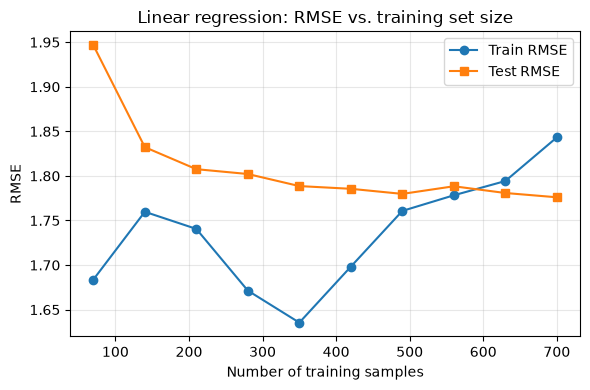

In [490]:

#LinearRegressionSWEEP.py

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error as rmse

#from data_generator import postfix

def postfix(N,d,sigma):
    """Converts parameters into a handy string, to be appended to file names."""
    return "_N_%d_d_%d" % (N,d) \
         + "_sig_%s" % str(sigma).replace(".","_")      


# Number of samples
N = 1000

# Noise variance 
sigma = 0.01


# Feature dimension
d = 5


psfx = postfix(N,d,sigma) 
      

X = np.load("X"+psfx+".npy")
y = np.load("y"+psfx+".npy")

print("Dataset has n=%d samples, each with d=%d features," % X.shape,"as well as %d labels." % y.shape[0])


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42)

print("Randomly split dataset to %d training and %d test samples" % (X_train.shape[0],X_test.shape[0]))

# --- AI-generated (Claude Sonnet 5.5, Anthropic) ---
# Train 10 models on fractions 10%,20%,...,100% of the training set
n_train = X_train.shape[0]
fractions = [0.1*k for k in range(1,11)]

sizes, rmse_train_list, rmse_test_list = [], [], []

for fr in fractions:
    m = int(round(fr*n_train))        # number of training samples used
    Xs, ys = X_train[:m], y_train[:m] # split is already shuffled, so first m is a random subset

    model = LinearRegression()
    model.fit(Xs, ys)

    rmse_train = rmse(ys, model.predict(Xs))          # on the m samples used for training
    rmse_test = rmse(y_test, model.predict(X_test))   # on the entire test set

    sizes.append(m)
    rmse_train_list.append(rmse_train)
    rmse_test_list.append(rmse_test)
    print("fr = %3d%%, m = %3d: Train RMSE = %f, Test RMSE = %f" % (round(fr*100), m, rmse_train, rmse_test))

plt.figure(figsize=(6,4))
plt.plot(sizes, rmse_train_list, "o-", label="Train RMSE")
plt.plot(sizes, rmse_test_list, "s-", label="Test RMSE")
plt.xlabel("Number of training samples")
plt.ylabel("RMSE")
plt.title("Linear regression: RMSE vs. training set size")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("rmse_vs_n.png", dpi=150)
plt.show()
# --- end AI-generated (Claude Sonnet 5.5, Anthropic) ---

### Question 4.3 
Run your code on a dataset generated by generate_data.py with N = 1000, d = 40,
and $\sigma$ = 0:01. Note that, by increasing the size of the input vector, you are in fact
adding variables that do not affect your labels; these are sometimes called nuisance
or redundant variables. For this dataset, plot the train and test RMSE as a function
of the number of training samples given to your model. Do you see any differences from Q4.2? Explain what you think is happening to cause this behavior. Do you think
that increasing the number of samples beyond 1000 would signiffcantly reduce the test error?

### Answer:

With extra features, the model overfits for lower number of samples leading to low training error and high test error. With more samples, test error falls and train error rises until both converge to the bias offset.


Dataset has n=1000 samples, each with d=40 features, as well as 1000 labels.
Randomly split dataset to 700 training and 300 test samples
fr =  10%, m =  70: Train RMSE = 0.782344, Test RMSE = 2.553466
fr =  20%, m = 140: Train RMSE = 1.252936, Test RMSE = 2.228897
fr =  30%, m = 210: Train RMSE = 1.473949, Test RMSE = 2.116938
fr =  40%, m = 280: Train RMSE = 1.547933, Test RMSE = 2.155503
fr =  50%, m = 350: Train RMSE = 1.618480, Test RMSE = 2.089867
fr =  60%, m = 420: Train RMSE = 1.669330, Test RMSE = 2.045826
fr =  70%, m = 490: Train RMSE = 1.695041, Test RMSE = 2.043388
fr =  80%, m = 560: Train RMSE = 1.669281, Test RMSE = 2.016909
fr =  90%, m = 630: Train RMSE = 1.657147, Test RMSE = 2.015099
fr = 100%, m = 700: Train RMSE = 1.664034, Test RMSE = 2.008328


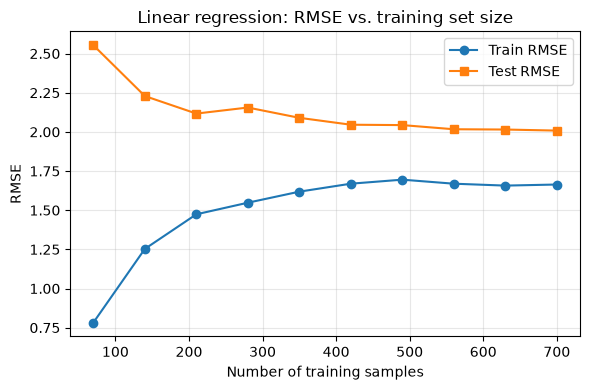

In [491]:
#LinearRegressionSWEEP.py
# N = 1000, d= 40, sigma = 0.01, sweep over training set eith more features
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error as rmse

#from data_generator import postfix

def postfix(N,d,sigma):
    """Converts parameters into a handy string, to be appended to file names."""
    return "_N_%d_d_%d" % (N,d) \
         + "_sig_%s" % str(sigma).replace(".","_")      


# Number of samples
N = 1000

# Noise variance 
sigma = 0.01


# Feature dimension
d = 40


psfx = postfix(N,d,sigma) 
      

X = np.load("X"+psfx+".npy")
y = np.load("y"+psfx+".npy")

print("Dataset has n=%d samples, each with d=%d features," % X.shape,"as well as %d labels." % y.shape[0])


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42)

print("Randomly split dataset to %d training and %d test samples" % (X_train.shape[0],X_test.shape[0]))

# --- AI-generated (Claude Sonnet 5.5, Anthropic) ---
# Train 10 models on fractions 10%,20%,...,100% of the training set
n_train = X_train.shape[0]
fractions = [0.1*k for k in range(1,11)]

sizes, rmse_train_list, rmse_test_list = [], [], []

for fr in fractions:
    m = int(round(fr*n_train))        # number of training samples used
    Xs, ys = X_train[:m], y_train[:m] # split is already shuffled, so first m is a random subset

    model = LinearRegression()
    model.fit(Xs, ys)

    rmse_train = rmse(ys, model.predict(Xs))          # on the m samples used for training
    rmse_test = rmse(y_test, model.predict(X_test))   # on the entire test set

    sizes.append(m)
    rmse_train_list.append(rmse_train)
    rmse_test_list.append(rmse_test)
    print("fr = %3d%%, m = %3d: Train RMSE = %f, Test RMSE = %f" % (round(fr*100), m, rmse_train, rmse_test))

plt.figure(figsize=(6,4))
plt.plot(sizes, rmse_train_list, "o-", label="Train RMSE")
plt.plot(sizes, rmse_test_list, "s-", label="Test RMSE")
plt.xlabel("Number of training samples")
plt.ylabel("RMSE")
plt.title("Linear regression: RMSE vs. training set size")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("rmse_vs_n.png", dpi=150)
plt.show()
# --- end AI-generated (Claude Sonnet 5.5, Anthropic) ---

### Question 4.4
Define a python function called lift that takes as input a vector __x__ $\in$ $\R^d$ and outputs
a vector __x'__ $\in$ $\R^d$' that contains x as well as all possible coordinate combinations of the
form xi * xj , for i; j $\in$ {1; : : : ; d}, with i >= j.

Starting with LinearRegressionSweep,py

Dataset has n=1000 samples, each with d=5 features, as well as 1000 labels.
Randomly split dataset to 700 training and 300 test samples
fr =  10%, m =  70: Train RMSE = 0.007980, Test RMSE = 0.011920
fr =  20%, m = 140: Train RMSE = 0.009054, Test RMSE = 0.010700
fr =  30%, m = 210: Train RMSE = 0.009497, Test RMSE = 0.010433
fr =  40%, m = 280: Train RMSE = 0.009515, Test RMSE = 0.010376
fr =  50%, m = 350: Train RMSE = 0.009724, Test RMSE = 0.010385
fr =  60%, m = 420: Train RMSE = 0.009744, Test RMSE = 0.010416
fr =  70%, m = 490: Train RMSE = 0.009865, Test RMSE = 0.010438
fr =  80%, m = 560: Train RMSE = 0.010012, Test RMSE = 0.010367
fr =  90%, m = 630: Train RMSE = 0.010015, Test RMSE = 0.010283
fr = 100%, m = 700: Train RMSE = 0.009915, Test RMSE = 0.010269


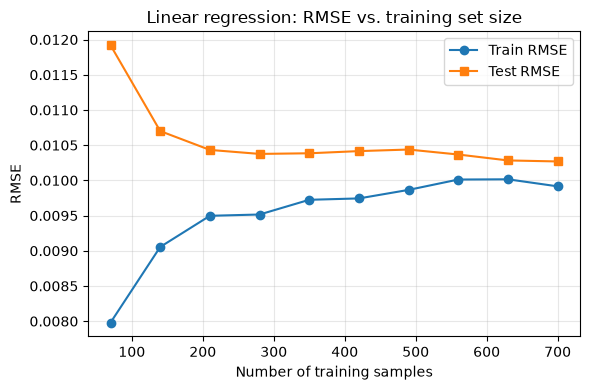

In [492]:
#LinearRegressionSWEEP_LIFTED.py 

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error as rmse

#from data_generator import postfix

def postfix(N,d,sigma):
    """Converts parameters into a handy string, to be appended to file names."""
    return "_N_%d_d_%d" % (N,d) \
         + "_sig_%s" % str(sigma).replace(".","_")      

# --- AI-generated (Claude, Anthropic) ---
def lift(x):
    x = np.asarray(x)
    d = x.shape[-1]
    quad = [x[..., i] * x[..., j] for i in range(d) for j in range(i + 1)]
    return np.concatenate([x, np.stack(quad, axis=-1)], axis=-1)
# --- end AI-generated ---


# Number of samples
N = 1000

# Noise variance 
sigma = 0.01


# Feature dimension
d = 5


psfx = postfix(N,d,sigma) 
      

X = np.load("X"+psfx+".npy")
y = np.load("y"+psfx+".npy")

print("Dataset has n=%d samples, each with d=%d features," % X.shape,"as well as %d labels." % y.shape[0])


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42)

print("Randomly split dataset to %d training and %d test samples" % (X_train.shape[0],X_test.shape[0]))

# --- AI-generated (Claude, Anthropic) ---
X_train_l = lift(X_train)   # shape (700, 20)
X_test_l = lift(X_test)     # shape (300, 20)
# --- end AI-generated ---


# --- AI-generated (Claude Sonnet 5.5, Anthropic) ---
# Train 10 models on fractions 10%,20%,...,100% of the training set
n_train_l = X_train_l.shape[0]
fractions = [0.1*k for k in range(1,11)]

sizes, rmse_train_list, rmse_test_list = [], [], []

for fr in fractions:
    m = int(round(fr*n_train))        # number of training samples used
    Xs, ys = X_train_l[:m], y_train[:m] # split is already shuffled, so first m is a random subset

    model = LinearRegression()
    model.fit(Xs, ys)

    rmse_train = rmse(ys, model.predict(Xs))          # on the m samples used for training
    rmse_test = rmse(y_test, model.predict(X_test_l))   # on the entire test set

    sizes.append(m)
    rmse_train_list.append(rmse_train)
    rmse_test_list.append(rmse_test)
    print("fr = %3d%%, m = %3d: Train RMSE = %f, Test RMSE = %f" % (round(fr*100), m, rmse_train, rmse_test))

plt.figure(figsize=(6,4))
plt.plot(sizes, rmse_train_list, "o-", label="Train RMSE")
plt.plot(sizes, rmse_test_list, "s-", label="Test RMSE")
plt.xlabel("Number of training samples")
plt.ylabel("RMSE")
plt.title("Linear regression: RMSE vs. training set size")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("rmse_vs_n.png", dpi=150)
plt.show()
# --- end AI-generated (Claude Sonnet 5.5, Anthropic) ---

 ### Question 4.5 
 Show that fun() can be written as $f(x') = \beta^Tx' + c$ for an appropriately defined vector $\beta \in R^d$' and constant $c \in \R$ and provide $\beta$ and $c$

$f(x) = 1.3 + 2x_0 - 1.1x_1 + 0.7x_2 + 1.2x_3 + 0.4x_0^2 - 1.5x_1 x_3 - 0.7x_4^2$

Answer:
For the lifting to $\R^{20}$, the coeficients of $x_k$ map to the following vector of $\beta$:

$\beta = [2, -1.1, 0.7, 1.2, 0, 0.4, 0, 0, 0, 0, 0, 0, -1.5, 0, 0, 0, 0, 0, 0 -0.7]^T \in \R^{20}$

$c = 1.3$

____________________________________________


### Question 4.6
_Define a python function liftDataset that takes as input a matrix __X__ $\in \R^d$ and
produces a matrix _X'_ $\in \R^{nxd'}$ that contains all rows of __X__, but lifted. You can use
function lift to implement this. Add the code in your report._

Dataset has n=1000 samples, each with d=5 features, as well as 1000 labels.
Randomly split dataset to 700 training and 300 test samples
Lifted dataset has shape (1000, 20)
fr =  10%, m =  70: Train RMSE = 0.007980, Test RMSE = 0.011920
fr =  20%, m = 140: Train RMSE = 0.009054, Test RMSE = 0.010700
fr =  30%, m = 210: Train RMSE = 0.009497, Test RMSE = 0.010433
fr =  40%, m = 280: Train RMSE = 0.009515, Test RMSE = 0.010376
fr =  50%, m = 350: Train RMSE = 0.009724, Test RMSE = 0.010385
fr =  60%, m = 420: Train RMSE = 0.009744, Test RMSE = 0.010416
fr =  70%, m = 490: Train RMSE = 0.009865, Test RMSE = 0.010438
fr =  80%, m = 560: Train RMSE = 0.010012, Test RMSE = 0.010367
fr =  90%, m = 630: Train RMSE = 0.010015, Test RMSE = 0.010283
fr = 100%, m = 700: Train RMSE = 0.009915, Test RMSE = 0.010269


Text(0, 0.5, 'RMSE')

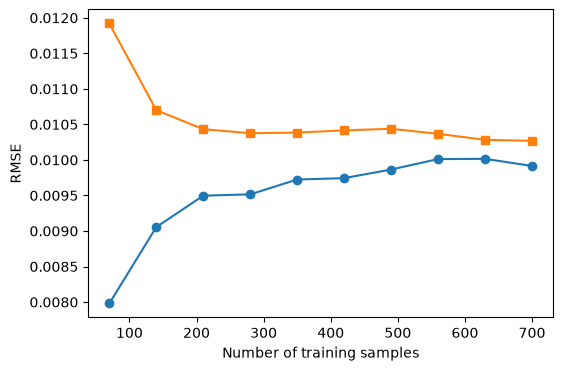

In [493]:
#LinearRegressionSWEEP_LIFT_DATASET.py

# --- AI-generated (Claude, Anthropic) ---
#def liftDataset(X):
#    """Takes X of shape (n, d) and returns X' of shape (n, d'), where row i of
#    X' is lift(X[i, :]). For d = 5, d' = 20."""
#    return np.array([lift(x) for x in X])
# --- end AI-generated ---




import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error as rmse

#from data_generator import postfix

def postfix(N,d,sigma):
    """Converts parameters into a handy string, to be appended to file names."""
    return "_N_%d_d_%d" % (N,d) \
         + "_sig_%s" % str(sigma).replace(".","_")      

# --- AI-generated (Claude, Anthropic) ---
def lift(x):
    x = np.asarray(x)
    d = x.shape[-1]
    quad = [x[..., i] * x[..., j] for i in range(d) for j in range(i + 1)]
    return np.concatenate([x, np.stack(quad, axis=-1)], axis=-1)

def liftDataset(X):
    """Takes X of shape (n, d) and returns X' of shape (n, d'), where row i of
    X' is lift(X[i, :]). For d = 5, d' = 20."""
    return np.array([lift(x) for x in X])
# --- end AI-generated ---

# Number of samples
N = 1000

# Noise variance 
sigma = 0.01


# Feature dimension
d = 5


psfx = postfix(N,d,sigma) 
      

X = np.load("X"+psfx+".npy")
y = np.load("y"+psfx+".npy")

print("Dataset has n=%d samples, each with d=%d features," % X.shape,"as well as %d labels." % y.shape[0])



X_train, X_test, y_train, y_test = train_test_split(
    X_lifted, y, test_size=0.30, random_state=42)

print("Randomly split dataset to %d training and %d test samples" % (X_train.shape[0],X_test.shape[0]))

# --- AI-generated (Claude, Anthropic) ---
X_lifted = liftDataset(X)   # shape (1000, 20)
print("Lifted dataset has shape", X_lifted.shape)
# --- end AI-generated ---

# --- AI-generated (Claude Sonnet 5.5, Anthropic) ---
# Train 10 models on fractions 10%,20%,...,100% of the training set
n_train = X_train.shape[0]
fractions = [0.1*k for k in range(1,11)]

sizes, rmse_train_list, rmse_test_list = [], [], []

for fr in fractions:
    m = int(round(fr*n_train))        # number of training samples used
    Xs, ys = X_train[:m], y_train[:m] # split is already shuffled, so first m is a random subset

    model = LinearRegression()
    model.fit(Xs, ys)

    rmse_train = rmse(ys, model.predict(Xs))          # on the m samples used for training
    rmse_test = rmse(y_test, model.predict(X_test))   # on the entire test set

    sizes.append(m)
    rmse_train_list.append(rmse_train)
    rmse_test_list.append(rmse_test)
    print("fr = %3d%%, m = %3d: Train RMSE = %f, Test RMSE = %f" % (round(fr*100), m, rmse_train, rmse_test))

plt.figure(figsize=(6,4))
plt.plot(sizes, rmse_train_list, "o-", label="Train RMSE")
plt.plot(sizes, rmse_test_list, "s-", label="Test RMSE")
plt.xlabel("Number of training samples")
plt.ylabel("RMSE")

### Question 4.7 
_Modify LinearRegressionSweepN so that it lifts matrixX generated by generate_data
right after reading it. This should happen before splitting the dataset into a train and
test set. Run your code on a dataset generated by generate_data.py with N = 1000,
$d = 5$, and $\sigma$ = 0:01. Plot the train and test RMSE as a function of the number of
training samples given to your model. How does this plot dffer from previous plots you
generated? Why? Obtain the parameters (coefficients and intercept) of your finally
trained model. Did you manage to learn function $fun$?_

After lifting, $fun$ is linear and the bias is zero, the RMSE value of .01 corresponds to the irreducible error $\sigma^{2}$. 

The model learned the parameters of fun: driving most coefficients to nearly zero, determined the intercept and elevated $\beta_{0,1,2,3,5,12,19}$ thus learning $f(x) = 1.3 + 2x_0 - 1.1x_1 + 0.7x_2 + 1.2x_3 + 0.4x_0^2 - 1.5x_1 x_3 - 0.7x_4^2$

Dataset has n=1000 samples, each with d=20 features, as well as 1000 labels.
Randomly split dataset to 700 training and 300 test samples
fr =  10%, m =  70: Train RMSE = 0.007980, Test RMSE = 0.011920
fr =  20%, m = 140: Train RMSE = 0.009054, Test RMSE = 0.010700
fr =  30%, m = 210: Train RMSE = 0.009497, Test RMSE = 0.010433
fr =  40%, m = 280: Train RMSE = 0.009515, Test RMSE = 0.010376
fr =  50%, m = 350: Train RMSE = 0.009724, Test RMSE = 0.010385
fr =  60%, m = 420: Train RMSE = 0.009744, Test RMSE = 0.010416
fr =  70%, m = 490: Train RMSE = 0.009865, Test RMSE = 0.010438
fr =  80%, m = 560: Train RMSE = 0.010012, Test RMSE = 0.010367
fr =  90%, m = 630: Train RMSE = 0.010015, Test RMSE = 0.010283
fr = 100%, m = 700: Train RMSE = 0.009915, Test RMSE = 0.010269


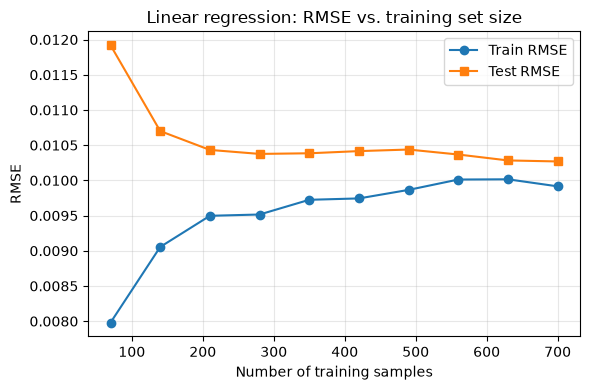

Intercept: 1.30010
beta0: 1.99994
beta1: -1.09996
beta2: 0.69968
beta3: 1.20015
beta4: 0.00044
beta5: 0.40014
beta6: 0.00001
beta7: -0.00010
beta8: 0.00025
beta9: -0.00014
beta10: -0.00030
beta11: -0.00006
beta12: -1.49967
beta13: -0.00073
beta14: -0.00031
beta15: 0.00061
beta16: -0.00002
beta17: -0.00036
beta18: -0.00098
beta19: -0.70011


In [494]:
#LinearRegressionSWEEP_LIFT_BEFORE_SPLIT.py

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error as rmse

#from data_generator import postfix

def postfix(N,d,sigma):
    """Converts parameters into a handy string, to be appended to file names."""
    return "_N_%d_d_%d" % (N,d) \
         + "_sig_%s" % str(sigma).replace(".","_")      

# --- AI-generated (Claude, Anthropic) ---
def lift(x):
    x = np.asarray(x)
    d = x.shape[-1]
    quad = [x[..., i] * x[..., j] for i in range(d) for j in range(i + 1)]
    return np.concatenate([x, np.stack(quad, axis=-1)], axis=-1)
# --- end AI-generated ---
def liftDataset(X):
    return np.array([lift(x) for x in X])
# --- end AI-generated ---

# Number of samples
N = 1000

# Noise variance 
sigma = 0.01


# Feature dimension
d = 5


psfx = postfix(N,d,sigma) 
      

X = np.load("X"+psfx+".npy")
y = np.load("y"+psfx+".npy")

# --- AI-generated (Claude, Anthropic) ---
X = liftDataset(X)   # shape (1000, 20)
# --- end AI-generated ---

print("Dataset has n=%d samples, each with d=%d features," % X.shape,"as well as %d labels." % y.shape[0])


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42)

print("Randomly split dataset to %d training and %d test samples" % (X_train.shape[0],X_test.shape[0]))

# --- AI-generated (Claude Sonnet 5.5, Anthropic) ---
# Train 10 models on fractions 10%,20%,...,100% of the training set
n_train = X_train.shape[0]
fractions = [0.1*k for k in range(1,11)]

sizes, rmse_train_list, rmse_test_list = [], [], []

for fr in fractions:
    m = int(round(fr*n_train))        # number of training samples used
    Xs, ys = X_train[:m], y_train[:m] # split is already shuffled, so first m is a random subset

    model = LinearRegression()
    model.fit(Xs, ys)

    rmse_train = rmse(ys, model.predict(Xs))          # on the m samples used for training
    rmse_test = rmse(y_test, model.predict(X_test))   # on the entire test set

    sizes.append(m)
    rmse_train_list.append(rmse_train)
    rmse_test_list.append(rmse_test)
    print("fr = %3d%%, m = %3d: Train RMSE = %f, Test RMSE = %f" % (round(fr*100), m, rmse_train, rmse_test))

plt.figure(figsize=(6,4))
plt.plot(sizes, rmse_train_list, "o-", label="Train RMSE")
plt.plot(sizes, rmse_test_list, "s-", label="Test RMSE")
plt.xlabel("Number of training samples")
plt.ylabel("RMSE")
plt.title("Linear regression: RMSE vs. training set size")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("rmse_vs_n.png", dpi=150)
plt.show()
# --- end AI-generated (Claude Sonnet 5.5, Anthropic) ---

# --- AI-generated (Claude Sonnet 5.5, Anthropic) ---
print("Intercept: %.5f" % model.intercept_)
for i, val in enumerate(model.coef_):
    print("beta%d: %.5f" % (i, val))
# --- end AI-generated (Claude Sonnet 5.5, Anthropic)---

### Question 4.8
_Repeat this now on a dataset (also lifted) generated by generate_data.py with N =
1000, d = 40, and σ = 0.01. How does the training and test error change as you increase the number 
of training samples? Obtain the parameters (coefficients and intercept) of your finally trained 
model. Did you manage to learn function fun? Do you think that increasing the number of samples 
beyond 1000 would improve the test error/the proximity of your learned model to the true function 
fun?_   

The training error is zero and the test error reduces based on the number of samples, this model is overfitting.

We did not learn the function $fun$, i.e beta0: 1.68980 for d = 40 and beta0: 1.99994 for d = 5 with N = 1000. 

I ran the model using 100,000 samples and $fun$ was learned by the model. It drove most coefficeints to zero, beta4: 0.00000 for example, and was very close to $fun$ coefficients, beta0: 1.99996.




Dataset has n=100000 samples, each with d=860 features, as well as 100000 labels.
Randomly split dataset to 70000 training and 30000 test samples
fr =  10%, m = 7000: Train RMSE = 0.009220, Test RMSE = 0.010653
fr =  20%, m = 14000: Train RMSE = 0.009619, Test RMSE = 0.010294
fr =  30%, m = 21000: Train RMSE = 0.009681, Test RMSE = 0.010215
fr =  40%, m = 28000: Train RMSE = 0.009769, Test RMSE = 0.010168
fr =  50%, m = 35000: Train RMSE = 0.009836, Test RMSE = 0.010127
fr =  60%, m = 42000: Train RMSE = 0.009869, Test RMSE = 0.010111
fr =  70%, m = 49000: Train RMSE = 0.009884, Test RMSE = 0.010103
fr =  80%, m = 56000: Train RMSE = 0.009905, Test RMSE = 0.010092
fr =  90%, m = 63000: Train RMSE = 0.009927, Test RMSE = 0.010084
fr = 100%, m = 70000: Train RMSE = 0.009935, Test RMSE = 0.010082


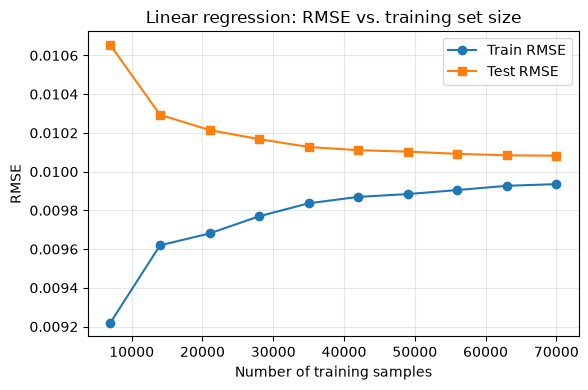

Intercept: 1.29984
beta0: 1.99996
beta1: -1.09994
beta2: 0.70003
beta3: 1.20002
beta4: 0.00000
beta5: 0.00002
beta6: -0.00003
beta7: 0.00003
beta8: 0.00002
beta9: 0.00001
beta10: 0.00002
beta11: -0.00007
beta12: 0.00002
beta13: 0.00006
beta14: 0.00003
beta15: -0.00003
beta16: -0.00001
beta17: -0.00008
beta18: -0.00005
beta19: -0.00002
beta20: -0.00000
beta21: -0.00004
beta22: -0.00002
beta23: -0.00001
beta24: 0.00001
beta25: 0.00006
beta26: -0.00003
beta27: 0.00003
beta28: -0.00003
beta29: -0.00015
beta30: -0.00002
beta31: 0.00001
beta32: 0.00002
beta33: -0.00003
beta34: -0.00005
beta35: 0.00001
beta36: 0.00003
beta37: 0.00001
beta38: 0.00001
beta39: 0.00003
beta40: 0.40000
beta41: -0.00002
beta42: -0.00002
beta43: 0.00006
beta44: -0.00001
beta45: 0.00002
beta46: -0.00004
beta47: -1.50003
beta48: -0.00001
beta49: 0.00003
beta50: 0.00005
beta51: 0.00002
beta52: -0.00004
beta53: -0.00003
beta54: -0.70000
beta55: 0.00004
beta56: -0.00007
beta57: -0.00002
beta58: 0.00001
beta59: -0.00000
b

In [ ]:
#LinearRegressionSWEEP_LIFT_BEFORE_SPLIT_D_40.py

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error as rmse

#from data_generator import postfix

def postfix(N,d,sigma):
    """Converts parameters into a handy string, to be appended to file names."""
    return "_N_%d_d_%d" % (N,d) \
         + "_sig_%s" % str(sigma).replace(".","_")      

# --- AI-generated (Claude, Anthropic) ---
def lift(x):
    x = np.asarray(x)
    d = x.shape[-1]
    quad = [x[..., i] * x[..., j] for i in range(d) for j in range(i + 1)]
    return np.concatenate([x, np.stack(quad, axis=-1)], axis=-1)

def liftDataset(X):
    return np.array([lift(x) for x in X])
# --- end AI-generated ---

# Number of samples
N = 1000
N = 100000

# Noise variance 
sigma = 0.01


# Feature dimension
d = 40


psfx = postfix(N,d,sigma) 
      

X = np.load("X"+psfx+".npy")
y = np.load("y"+psfx+".npy")

# --- AI-generated (Claude, Anthropic) ---
X = liftDataset(X)   # shape (1000, 20)
# --- end AI-generated ---

print("Dataset has n=%d samples, each with d=%d features," % X.shape,"as well as %d labels." % y.shape[0])


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42)

print("Randomly split dataset to %d training and %d test samples" % (X_train.shape[0],X_test.shape[0]))

# --- AI-generated (Claude Sonnet 5.5, Anthropic) ---
# Train 10 models on fractions 10%,20%,...,100% of the training set
n_train = X_train.shape[0]
fractions = [0.1*k for k in range(1,11)]

sizes, rmse_train_list, rmse_test_list = [], [], []

for fr in fractions:
    m = int(round(fr*n_train))        # number of training samples used
    Xs, ys = X_train[:m], y_train[:m] # split is already shuffled, so first m is a random subset

    model = LinearRegression()
    model.fit(Xs, ys)

    rmse_train = rmse(ys, model.predict(Xs))          # on the m samples used for training
    rmse_test = rmse(y_test, model.predict(X_test))   # on the entire test set

    sizes.append(m)
    rmse_train_list.append(rmse_train)
    rmse_test_list.append(rmse_test)
    print("fr = %3d%%, m = %3d: Train RMSE = %f, Test RMSE = %f" % (round(fr*100), m, rmse_train, rmse_test))

plt.figure(figsize=(6,4))
plt.plot(sizes, rmse_train_list, "o-", label="Train RMSE")
plt.plot(sizes, rmse_test_list, "s-", label="Test RMSE")
plt.xlabel("Number of training samples")
plt.ylabel("RMSE")
plt.title("Linear regression: RMSE vs. training set size")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("rmse_vs_n.png", dpi=150)
plt.show()
# --- end AI-generated (Claude Sonnet 5.5, Anthropic) ---

# --- AI-generated (Claude Sonnet 5.5, Anthropic) ---
print("Intercept: %.5f" % model.intercept_)
for i, val in enumerate(model.coef_):
    print("beta%d: %.5f" % (i, val))
# --- end AI-generated (Claude Sonnet 5.5, Anthropic)---